# 03_final_surrogate: Step 3 - pick and save the deployed surrogate, compare against baselines.

```
Candidates: default XGBoost, XGBoost tuned by PSO / GA / HHO, the best tuned model
with physics monotone constraints, and a weighted ensemble around the best tuned
XGBoost. Selection uses only the training days (grouped CV RMSE); the held-out
test days are reported, never used to choose.
Rule: the monotone model is preferred when its CV RMSE is within 2 % of the best,
because the optimiser must not exploit non-physical wiggles of the surrogate.
Outputs -> outputs/surrogate/, outputs/models/surrogate.joblib, figures.
```

Dikonversi dari `scripts/03_final_surrogate.py`. Jalankan dari folder `notebooks/`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent   # notebook runs from AI-OBEP-MLPaper/notebooks
sys.path.insert(0, str(ROOT / "src"))
from obep_mlpaper.data import FEATURES, TARGET, day_split, hourly_dataset
from obep_mlpaper.plotstyle import ALGO_COLORS, INK2, NEUTRAL, SERIES, plt
from obep_mlpaper.surrogate import (Surrogate, WeightedEnsemble, grouped_cv_predict, make_xgb,
                                    metrics, model_zoo)

out = ROOT / "outputs" / "surrogate"
fig_dir = ROOT / "outputs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
best = json.loads((out / "best_xgb_params.json").read_text())

d = hourly_dataset()
tr, te = day_split(d)
X, y, g = d[FEATURES].to_numpy(), d[TARGET].to_numpy(), d["day"].to_numpy()
op_te = d["hvac_schedule"].to_numpy()[te] == 1
op_tr = d["hvac_schedule"].to_numpy()[tr] == 1

# Physics monotone constraints: energy never decreases with occupants, outdoor T, solar.
MONO = {"occupant_count": 1, "dry_bulb_temp": 1, "global_horizontal_solar_radiation": 1}
mono = "(" + ",".join(str(MONO.get(f, 0)) for f in FEATURES) + ")"
bp = best["params"]

cands = {
    "XGBoost (default)": lambda: model_zoo()["XGBoost"],
    "XGBoost-PSO": lambda: make_xgb(best["per_algo"]["PSO"]),
    "XGBoost-GA": lambda: make_xgb(best["per_algo"]["GA"]),
    "XGBoost-HHO": lambda: make_xgb(best["per_algo"]["HHO"]),
    f"XGBoost-{best['algo']} + monotone": lambda: make_xgb({**bp, "monotone_constraints": mono}),
}
ens_makers = {"xgb": lambda: make_xgb(bp), "et": lambda: model_zoo()["ExtraTrees"],
              "lgbm": lambda: model_zoo()["LightGBM"], "rf": lambda: model_zoo()["RandomForest"]}

In [2]:
class _Ens:
    def fit(self, Xa, ya, ga=None):
        self.e = WeightedEnsemble(ens_makers).fit(Xa, ya, ga)
        return self

    def predict(self, Xa):
        return self.e.predict(Xa)


rows, fitted, preds = [], {}, {}
for name, mk in list(cands.items()) + [(f"WeightedEnsemble (XGBoost-{best['algo']}+ET+LGBM+RF)", None)]:
    if mk is None:   # ensemble needs groups for its inner OOF weights
        oof = np.zeros(tr.sum())
        from sklearn.model_selection import GroupKFold
        for a, b in GroupKFold(5).split(X[tr], y[tr], g[tr]):
            oof[b] = _Ens().fit(X[tr][a], y[tr][a], g[tr][a]).predict(X[tr][b])
        m = _Ens().fit(X[tr], y[tr], g[tr])
    else:
        oof = grouped_cv_predict(mk, X[tr], y[tr], g[tr])
        m = mk().fit(X[tr], y[tr])
    p = np.clip(m.predict(X[te]), 0, None)
    cv = metrics(y[tr], np.clip(oof, 0, None))
    tm = metrics(y[te], p)
    rows.append(dict(model=name, cv_RMSE=cv["RMSE"], cv_R2=cv["R2"],
                     cv_R2_operating=metrics(y[tr][op_tr], oof[op_tr])["R2"],
                     **{f"test_{k}": v for k, v in tm.items()},
                     test_R2_operating=metrics(y[te][op_te], p[op_te])["R2"]))
    fitted[name], preds[name] = m, p
    print(f"{name:52s} CV-RMSE={cv['RMSE']:.2f} CV-R2={cv['R2']:.3f} | test R2={tm['R2']:.3f} "
          f"op={rows[-1]['test_R2_operating']:.3f} CV(RMSE)={tm['CVRMSE_pct']:.1f}% NMBE={tm['NMBE_pct']:.1f}%")
res = pd.DataFrame(rows)

# Selection on training-day CV only
best_cv = res.cv_RMSE.min()
mono_name = f"XGBoost-{best['algo']} + monotone"
mono_cv = float(res.loc[res.model == mono_name, "cv_RMSE"].iloc[0])
chosen = mono_name if mono_cv <= 1.02 * best_cv else res.loc[res.cv_RMSE.idxmin(), "model"]
res["deployed"] = res.model == chosen
res.to_csv(out / "final_surrogate_comparison.csv", index=False)
print("\nDeployed surrogate:", chosen)

meta = dict(model=chosen, features=FEATURES, target="HVAC power density [W/m2], hourly",
            train_days=sorted(set(g[tr])), test_days=sorted(set(g[te])),
            test_metrics={k: v for k, v in res[res.deployed].iloc[0].items() if k.startswith("test_")},
            xgb_params=bp, tuned_by=best["algo"], monotone_constraints=MONO if "monotone" in chosen else None)
models_dir = ROOT / "outputs" / "models"
Surrogate(fitted[chosen], FEATURES, meta).save(models_dir / "surrogate.joblib")
(models_dir / "surrogate_meta.json").write_text(json.dumps(meta, indent=2, default=float))

XGBoost (default)                                    CV-RMSE=7.32 CV-R2=0.782 | test R2=0.615 op=-0.011 CV(RMSE)=67.8% NMBE=-29.2%


XGBoost-PSO                                          CV-RMSE=6.89 CV-R2=0.807 | test R2=0.709 op=0.242 CV(RMSE)=59.0% NMBE=-26.0%


XGBoost-GA                                           CV-RMSE=6.89 CV-R2=0.807 | test R2=0.708 op=0.240 CV(RMSE)=59.0% NMBE=-25.9%


XGBoost-HHO                                          CV-RMSE=6.88 CV-R2=0.808 | test R2=0.690 op=0.188 CV(RMSE)=60.9% NMBE=-25.6%


XGBoost-HHO + monotone                               CV-RMSE=7.08 CV-R2=0.797 | test R2=0.664 op=0.118 CV(RMSE)=63.4% NMBE=-25.2%


WeightedEnsemble (XGBoost-HHO+ET+LGBM+RF)            CV-RMSE=6.98 CV-R2=0.802 | test R2=0.689 op=0.186 CV(RMSE)=60.9% NMBE=-25.9%

Deployed surrogate: XGBoost-HHO


1587

In [3]:
# ---------------- Figures
conv = pd.read_csv(out / "metaheuristic_convergence.csv", index_col=0)
fig, ax = plt.subplots(figsize=(4.6, 3.2))
for algo, c in ALGO_COLORS.items():
    cols = [k for k in conv.columns if k.startswith(algo + "_")]
    mu, lo, hi = conv[cols].mean(axis=1), conv[cols].min(axis=1), conv[cols].max(axis=1)
    ax.plot(conv.index + 1, mu, color=c, lw=2, label=f"{algo} (mean of {len(cols)} seeds)")
    ax.fill_between(conv.index + 1, lo, hi, color=c, alpha=0.12, lw=0)
default_cv = float(res.loc[res.model == "XGBoost (default)", "cv_RMSE"].iloc[0])
ax.axhline(default_cv, color=NEUTRAL, lw=1, ls="--")
ax.text(conv.index[-1], default_cv, "default XGBoost", color=INK2, ha="right", va="bottom", fontsize=8)
ax.set(xlabel="Function evaluations", ylabel="Grouped-CV RMSE [W/m²]",
       title="Hyperparameter search convergence")
ax.set_ylim(top=default_cv * 1.06)
ax.legend(fontsize=8)
fig.savefig(fig_dir / "fig_metaheuristic_convergence.png")

fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.4))
p = preds[chosen]
ax[0].scatter(y[te], p, s=10, color=SERIES[0], alpha=0.6, edgecolor="none")
lim = [0, max(y[te].max(), p.max()) * 1.05]
ax[0].plot(lim, lim, color=NEUTRAL, lw=1, ls="--")
r2 = res[res.deployed].iloc[0]
ax[0].set(xlim=lim, ylim=lim, xlabel="Measured [W/m²]", ylabel="Predicted [W/m²]",
          title=f"Held-out days: R² = {r2.test_R2:.3f}, CV(RMSE) = {r2.test_CVRMSE_pct:.1f}%")
tt = d[te].assign(pred=p)
prof = tt.groupby(tt.ts.dt.hour)[[TARGET, "pred"]].mean()
ax[1].plot(prof.index, prof[TARGET], color=INK2, lw=2, label="Measured")
ax[1].plot(prof.index, prof["pred"], color=SERIES[0], lw=2, ls="--", label="Surrogate")
ax[1].set(xlabel="Hour of day", ylabel="Mean HVAC power [W/m²]", title="Mean daily profile, held-out days")
ax[1].legend()
fig.tight_layout()
fig.savefig(fig_dir / "fig_surrogate_test.png")
print("figures ->", fig_dir)

figures -> C:\Users\yohan\OneDrive - mail.unnes.ac.id\Penelitian AI-OBEP\AI-OBEP\AI-OBEP\AI-OBEP-MLPaper\outputs\figures


## Gambar yang dihasilkan

fig_metaheuristic_convergence.png


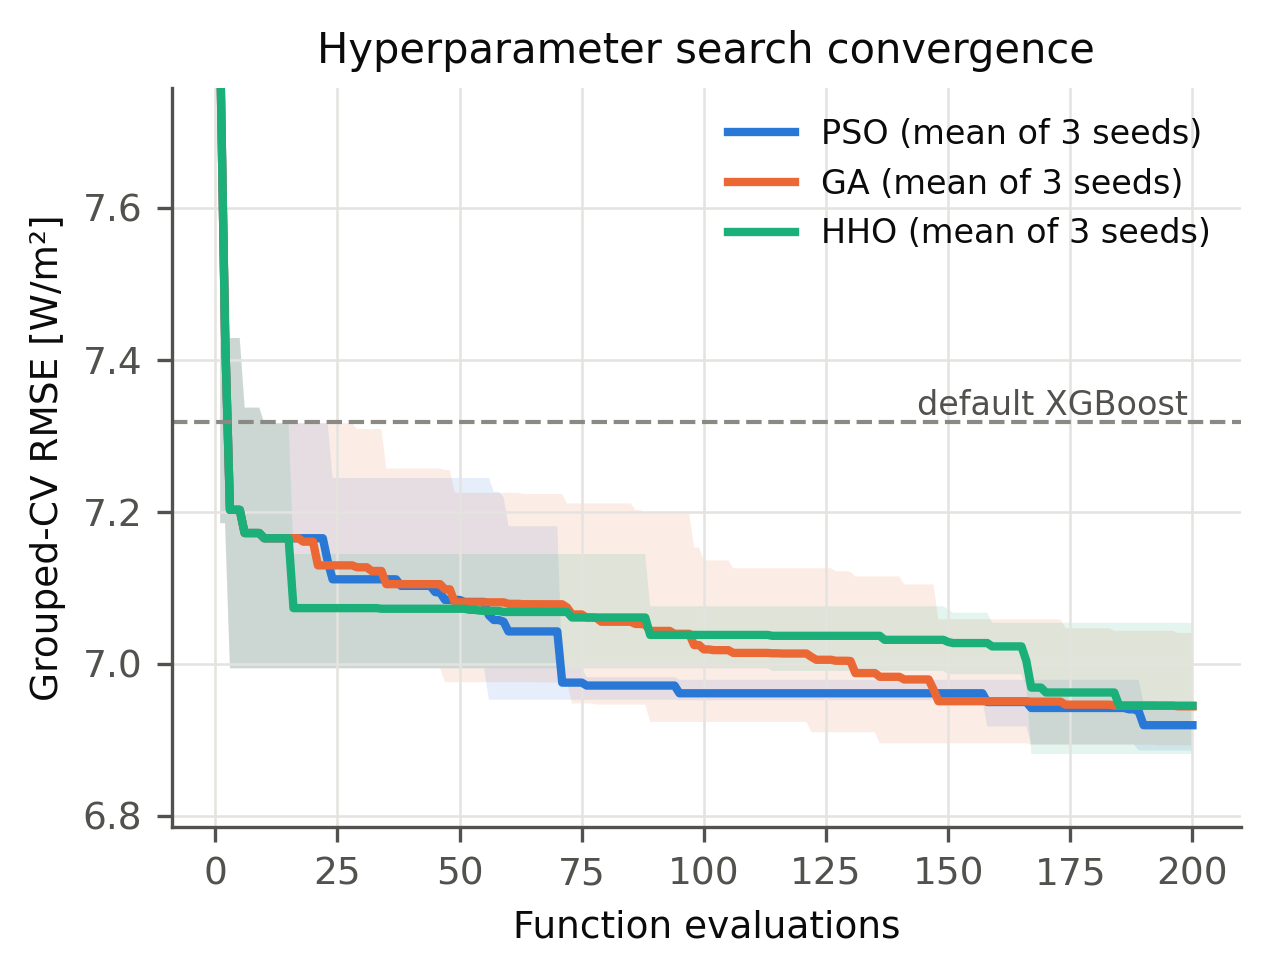

fig_surrogate_test.png


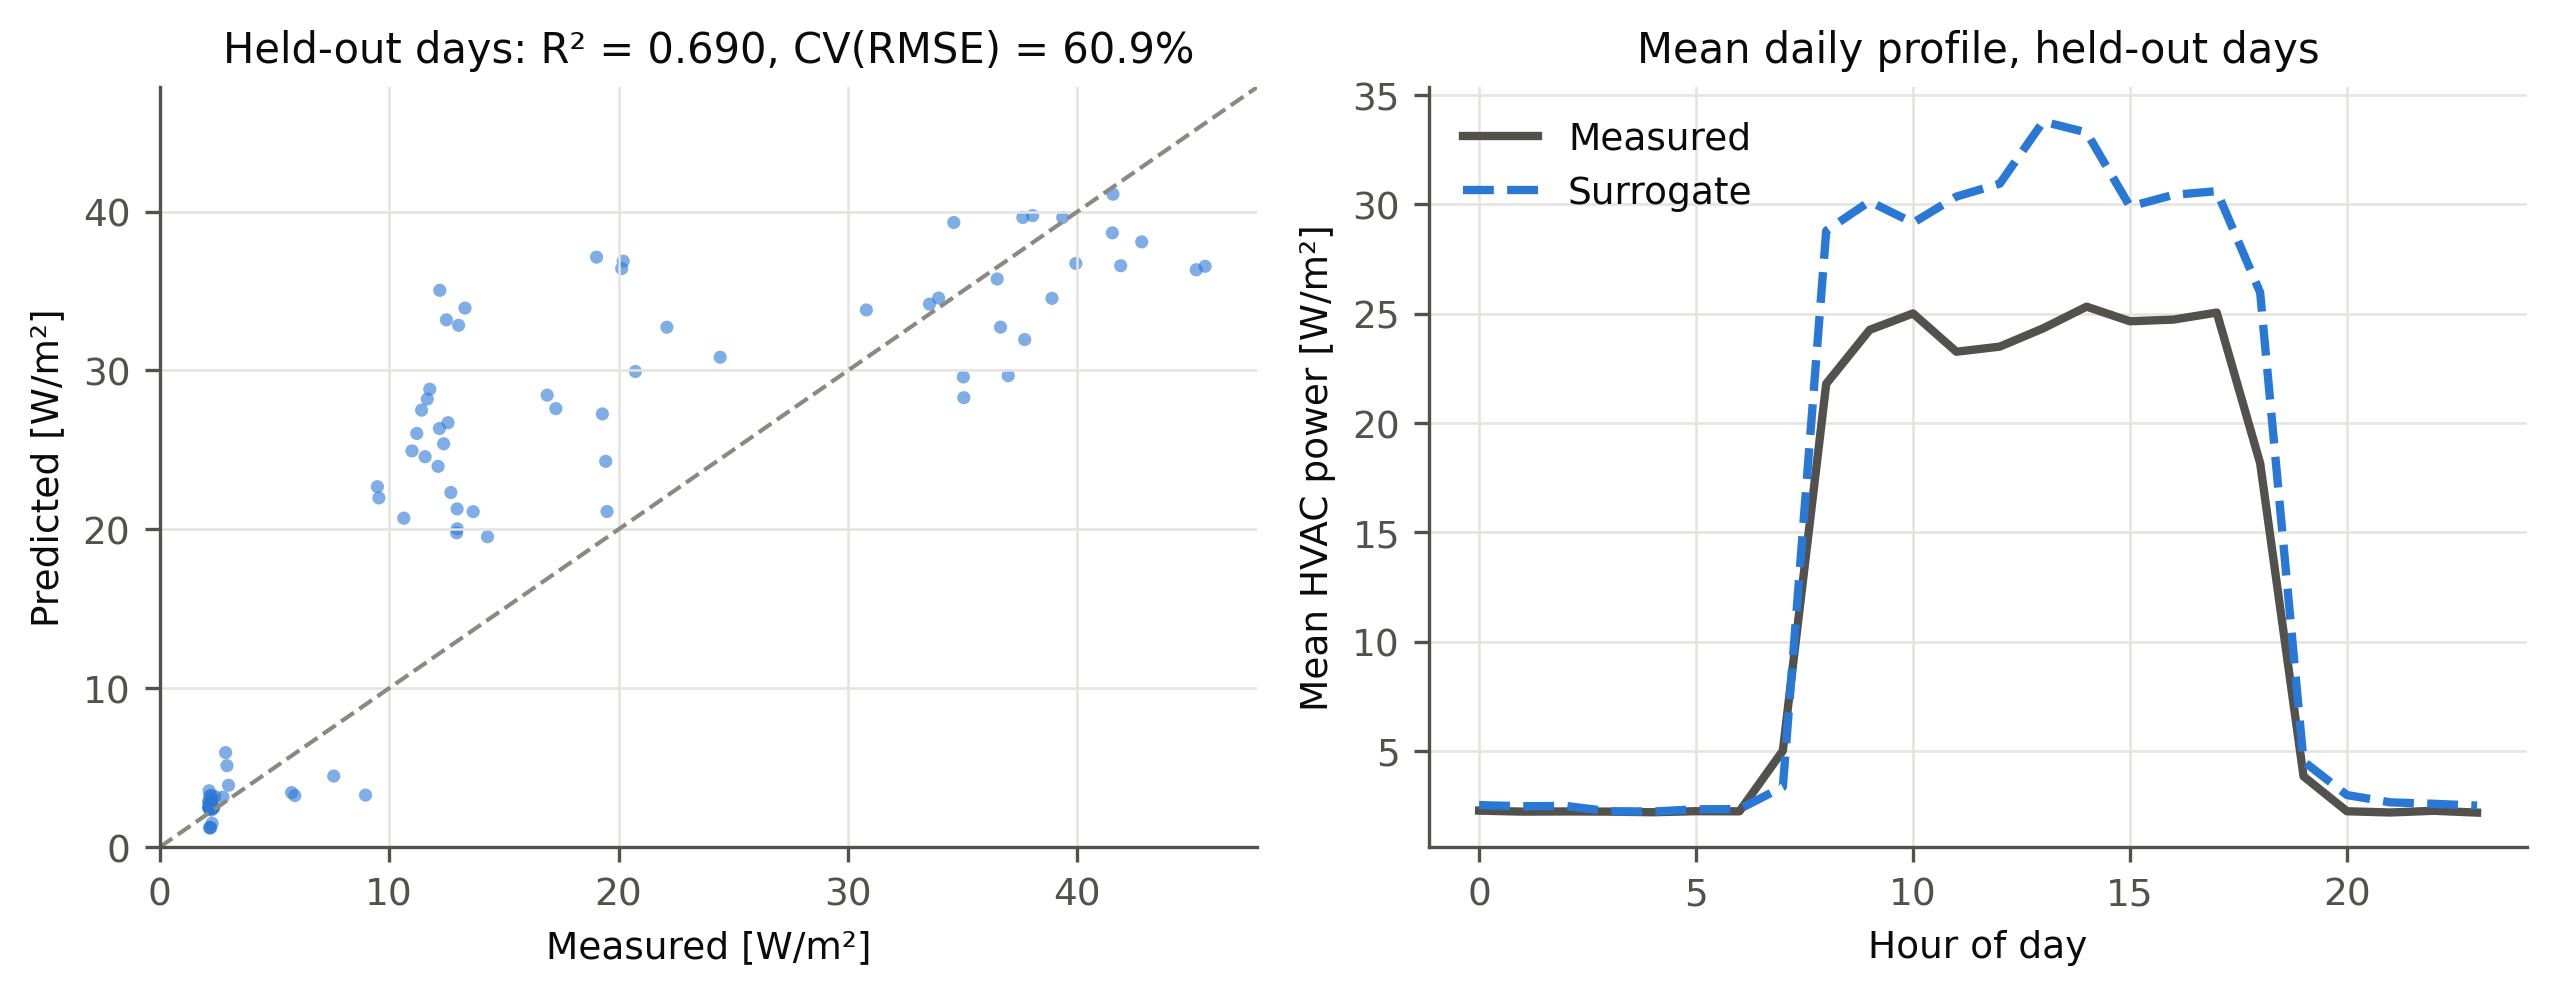

In [4]:
from IPython.display import Image, display
for f in ['fig_metaheuristic_convergence.png', 'fig_surrogate_test.png']:
    print(f)
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f), width=800))